# 03 Land and job access

Developed land from NLCD rasters, and jobs within 30 minutes by car.

**Inputs**
- `data/raw/5500/landcover/nlcd_<year>_pa.tif`
- `data/raw/5500/jobs/pa_wac_2024.csv.gz`
- `data/raw/5500/jobs/pa_xwalk.csv.gz` (block lat/lon, downloaded here if missing)
- `data/raw/boundaries/CenPop2020_Mean_TR42.txt`
- `data/processed/tracts_2020.gpkg`

**Output (the tool reads this)**
- `data/processed/access_tract.csv  (GEOID, dev_2010, dev_2019, dev_2025, jobs_30min)`

Run `python musa5500/get_data.py` first.

In [1]:
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
from common import RAW, OUT, ACS_YEARS, download

FIG = ROOT / "musa5500" / "docs" / "figures"

## Developed land (zonal stats)

- Reproject tracts to the raster CRS (EPSG:5070)
- zonal_stats(..., categorical=True)
- Developed = classes 21, 22, 23, 24
- Share = developed pixels / land pixels. Land = every class except open water (11). 250 = no data
- Note: the first 2019 mosaic had two empty 60 km tiles (parts of Chester, Delaware, and Tioga counties). Those two tiles were downloaded again from the same USGS service on Nov 10 2026 and pasted into `nlcd_2019_pa.tif`. After the fix no year has a no-data pixel where another year has data
- Also keep the share of high-intensity (23, 24) pixels

In [2]:
from rasterstats import zonal_stats
tracts = gpd.read_file(OUT / "tracts_2020.gpkg").to_crs(5070)

DEV = [21, 22, 23, 24]
CACHE = RAW / "5500" / "landcover"   # pixel counts per tract are saved here so a rerun is fast
land = tracts[["GEOID"]].copy()
for year in [2010, 2019, 2025]:
    t0 = time.time()
    tif = RAW / "5500" / "landcover" / f"nlcd_{year}_pa.tif"
    cf = CACHE / f"zonal_counts_{year}.csv"
    if cf.exists():
        cnt = pd.read_csv(cf, dtype={"GEOID": str}).set_index("GEOID").loc[tracts.GEOID].reset_index(drop=True)
        cnt.columns = cnt.columns.astype(int)
    else:
        zs = zonal_stats(tracts.geometry, tif, categorical=True, nodata=250)
        cnt = pd.DataFrame(zs).fillna(0)
        cnt.assign(GEOID=tracts.GEOID.values).to_csv(cf, index=False)
    landpx = cnt.drop(columns=[c for c in cnt.columns if c in (11, 250)]).sum(axis=1)
    land[f"dev_{year}"] = cnt[[c for c in DEV if c in cnt]].sum(axis=1) / landpx
    land[f"devhi_{year}"] = cnt[[c for c in [23, 24] if c in cnt]].sum(axis=1) / landpx
    print(year, f"{time.time() - t0:.0f}s", "median dev share", round(land[f"dev_{year}"].median(), 3))
land["dev_change_10_25"] = land.dev_2025 - land.dev_2010
land.describe().round(3)

2010 0s median dev share 0.782
2019 0s median dev share 0.793
2025 0s median dev share 0.805


,dev_2010,devhi_2010,dev_2019,devhi_2019,dev_2025,devhi_2025,dev_change_10_25
count,3445.000,3445.000,3445.000,3445.000,3445.000,3445.000,3445.000
mean,0.635,0.316,0.643,0.318,0.648,0.319,0.013
std,0.358,0.325,0.355,0.323,0.354,0.322,0.023
min,0.019,0.000,0.019,0.000,0.019,0.000,-0.134
25%,0.234,0.028,0.249,0.030,0.259,0.031,0.000
50%,0.782,0.190,0.793,0.200,0.805,0.203,0.004
75%,0.984,0.535,0.985,0.536,0.986,0.534,0.015
max,1.000,1.000,1.000,1.000,1.000,1.000,0.408


### Statewide developed land

- Pixel totals across all tracts, so big rural tracts count by their size

In [3]:
tot = {}
for year in [2010, 2019, 2025]:
    zs = zonal_stats(tracts.dissolve().geometry, RAW / "5500" / "landcover" / f"nlcd_{year}_pa.tif",
                     categorical=True, nodata=250)[0]
    landpx = sum(v for k, v in zs.items() if k not in (11, 250))
    devpx = sum(zs.get(k, 0) for k in DEV)
    tot[year] = {"developed_km2": devpx * 900 / 1e6, "share_of_land": devpx / landpx}
tot = pd.DataFrame(tot).T
tot["developed_km2"] = tot.developed_km2.round(0)
tot["share_of_land"] = tot.share_of_land.round(4)
tot

,developed_km2,share_of_land
2010,16745.0,0.1442
2019,17374.0,0.1497
2025,17812.0,0.1534


In [4]:
top = land.nlargest(10, "dev_change_10_25")[["GEOID", "dev_2010", "dev_2025", "dev_change_10_25"]]
print("Share of tracts with more developed land in 2025 than 2010:", round((land.dev_change_10_25 > 0).mean(), 3))
top.round(3)

Share of tracts with more developed land in 2025 than 2010: 0.719


,GEOID,dev_2010,dev_2025,dev_change_10_25
1389,42095017404,0.378,0.786,0.408
310,42133021801,0.584,0.812,0.228
453,42041011607,0.687,0.913,0.226
2270,42041011807,0.682,0.898,0.216
229,42041011500,0.797,0.991,0.194
3024,42133022403,0.469,0.648,0.180
2542,42091208304,0.450,0.615,0.165
2455,42079218000,0.488,0.637,0.149
2237,42019912304,0.627,0.774,0.148
116,42043023900,0.714,0.853,0.139


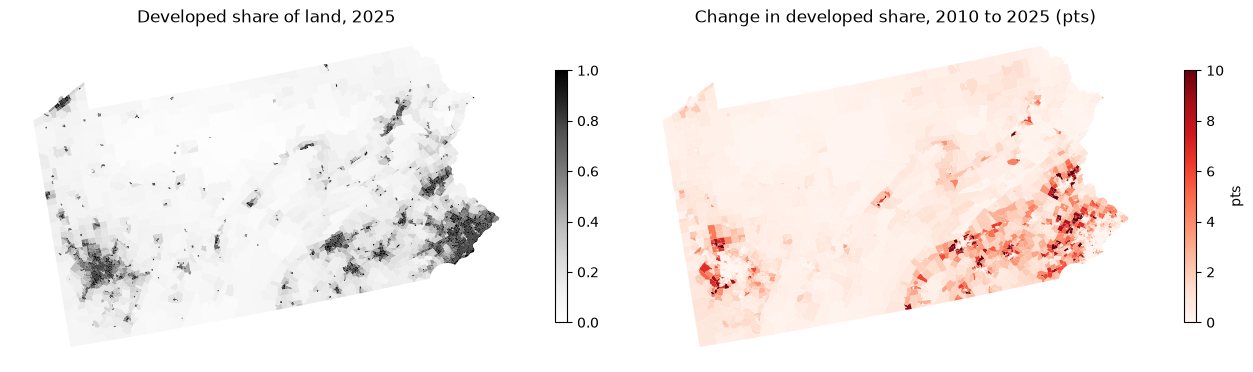

In [5]:
g = tracts.merge(land, on="GEOID")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
g.plot(column="dev_2025", ax=axes[0], cmap="Greys", vmin=0, vmax=1, legend=True, legend_kwds={"shrink": 0.6})
axes[0].set_title("Developed share of land, 2025")
g.plot(column=g.dev_change_10_25 * 100, ax=axes[1], cmap="Reds", vmin=0, vmax=10, legend=True,
       legend_kwds={"shrink": 0.6, "label": "pts"})
axes[1].set_title("Change in developed share, 2010 to 2025 (pts)")
for a in axes:
    a.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "03_developed.png", dpi=150)

## Job access with OSMnx (one metro first)

- Start with one metro (e.g. Harrisburg). Then loop over the others
- ox.graph.graph_from_polygon(metro, network_type='drive')
- ox.routing.add_edge_speeds, then add_edge_travel_times
- Tract centers -> nearest nodes. Job blocks -> nearest nodes
- networkx single_source_dijkstra_path_length, cutoff=1800 (30 min)
- Only the largest strongly connected part of the network is used (a first run had 2 tracts snap to cut-off nodes and get 0 jobs)
- Block lat/lon is in the LODES crosswalk file (pa_xwalk.csv.gz)

Scope (to keep run time bounded):
- Two metros: Harrisburg (Cumberland and Dauphin counties) and Philadelphia city
- Both hold a MUSA 6950 pilot county (Cumberland, Philadelphia)
- The road network is clipped to the metro counties plus a 15 km buffer, inside Pennsylvania. Jobs farther out or in other states (New Jersey, Delaware) are missed, so edge tracts are undercounted
- Speeds are OSM speed limits or OSMnx defaults by road type. No traffic. Real 30-minute reach at rush hour is smaller
- Jobs = LODES 2024 jobs by work block (WAC, C000)
- Graphs are cached in `data/raw/5500/osm/` (not committed)
- Nov 10 2026 run: the public Overpass server was at capacity for most of the day. Philadelphia downloaded. Harrisburg failed after many tries (502 errors and timeouts), even after cutting it to Cumberland + Dauphin. The code skips a metro it cannot get. Rerun this notebook later to add Harrisburg

In [6]:
import osmnx as ox
import networkx as nx

OSM = RAW / "5500" / "osm"
OSM.mkdir(parents=True, exist_ok=True)
ox.settings.cache_folder = str(OSM / "cache")
ox.settings.use_cache = True
ox.settings.log_console = False
ox.settings.requests_timeout = 180
ox.settings.max_query_area_size = 1_000_000_000  # smaller Overpass pieces (1,000 km2) so a busy server can answer

xwf = download("https://lehd.ces.census.gov/data/lodes/LODES8/pa/pa_xwalk.csv.gz",
               RAW / "5500" / "jobs" / "pa_xwalk.csv.gz")
xwalk = pd.read_csv(xwf, dtype={"tabblk2020": str}, usecols=["tabblk2020", "blklatdd", "blklondd"])
wac = pd.read_csv(RAW / "5500" / "jobs" / "pa_wac_2024.csv.gz", dtype={"w_geocode": str}, usecols=["w_geocode", "C000"])
blocks = wac.merge(xwalk, left_on="w_geocode", right_on="tabblk2020")
print(len(wac), "job blocks,", len(blocks), "with lat/lon,", int(blocks.C000.sum()), "jobs")

cen = pd.read_csv(RAW / "boundaries" / "CenPop2020_Mean_TR42.txt", dtype=str, encoding="utf-8-sig")
cen["GEOID"] = cen.STATEFP + cen.COUNTYFP + cen.TRACTCE
cen[["LATITUDE", "LONGITUDE"]] = cen[["LATITUDE", "LONGITUDE"]].astype(float)
counties = gpd.read_file(OUT / "counties_2020.gpkg")
pa = counties.to_crs(5070).dissolve().geometry.iloc[0]

OVERPASS = ["https://overpass-api.de/api", "https://overpass.private.coffee/api", "https://overpass.kumi.systems/api"]
TRIES = 1  # Overpass was down on Nov 10 2026. Raise this to retry more
METROS = {
    "Harrisburg": ["42041", "42043"],
    "Philadelphia": ["42101"],
}


def job_access(name, fips, buffer_m=15_000, cutoff=1800):
    t0 = time.time()
    f = OSM / f"{name.lower()}_drive.graphml"
    area = counties[counties.GEOID.isin(fips)].to_crs(5070).dissolve().geometry.iloc[0]
    poly = area.buffer(buffer_m).intersection(pa)
    poly_ll = gpd.GeoSeries([poly], crs=5070).to_crs(4326).iloc[0]
    if f.exists():
        G = ox.load_graphml(f)
    else:
        # The public Overpass server is often busy. Try mirrors with a pause between tries
        G = None
        for attempt in range(TRIES):
            ox.settings.overpass_url = OVERPASS[attempt % len(OVERPASS)]
            try:
                G = ox.graph.graph_from_polygon(poly_ll, network_type="drive")
                break
            except Exception as e:
                print("  retry", attempt, ox.settings.overpass_url, type(e).__name__)
                time.sleep(60)
        if G is None:
            print(f"{name}: could not get the road network from Overpass. Skipped")
            return None
        G = ox.routing.add_edge_speeds(G)
        G = ox.routing.add_edge_travel_times(G)
        ox.save_graphml(G, f)
    # Keep the biggest strongly connected part, so no tract snaps to a dead-end island
    G = ox.truncate.largest_component(G, strongly=True)
    print(f"{name}: {len(G):,} nodes, {G.number_of_edges():,} edges, graph ready in {time.time() - t0:.0f}s")

    # Jobs inside the graph area -> nearest node
    b = gpd.GeoDataFrame(blocks, geometry=gpd.points_from_xy(blocks.blklondd, blocks.blklatdd), crs=4326)
    b = b[b.within(poly_ll)]
    b["node"] = ox.distance.nearest_nodes(G, b.blklondd.values, b.blklatdd.values)
    node_jobs = b.groupby("node").C000.sum()

    # Tract centers (population-weighted) -> nearest node
    tc = cen[cen.GEOID.str[:5].isin(fips)].copy()
    tc["node"] = ox.distance.nearest_nodes(G, tc.LONGITUDE.values, tc.LATITUDE.values)
    out = []
    for geoid, node in zip(tc.GEOID, tc.node):
        reach = nx.single_source_dijkstra_path_length(G, node, cutoff=cutoff, weight="travel_time")
        out.append((geoid, float(node_jobs.reindex(list(reach)).sum())))
    res = pd.DataFrame(out, columns=["GEOID", "jobs_30min"])
    res["metro"] = name
    res["jobs_in_area"] = int(b.C000.sum())
    print(f"{name}: {len(res)} tracts done in {time.time() - t0:.0f}s total")
    return res


acc = pd.concat([job_access(n, f) for n, f in METROS.items()], ignore_index=True)  # skipped metros return None
acc.groupby("metro").jobs_30min.describe().round(0)

  have  data/raw/5500/jobs/pa_xwalk.csv.gz


102831 job blocks, 102831 with lat/lon, 5957234 jobs


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:451: RuntimeWarning: invalid value encountered in union
  return lib.union(a, b, **kwargs)


  retry 0 https://overpass-api.de/api ConnectionError


Harrisburg: could not get the road network from Overpass. Skipped


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


Philadelphia: 66,185 nodes, 170,760 edges, graph ready in 26s


Philadelphia: 408 tracts done in 96s total


,count,mean,std,min,25%,50%,75%,max
metro,,,,,,,,
Philadelphia,408.0,1384384.0,89608.0,1071537.0,1328362.0,1407502.0,1449923.0,1521510.0


In [7]:
acc["share_of_area_jobs"] = acc.jobs_30min / acc.jobs_in_area
acc.groupby("metro").share_of_area_jobs.describe().round(3)

,count,mean,std,min,25%,50%,75%,max
metro,,,,,,,,
Philadelphia,408.0,0.89,0.058,0.688,0.854,0.904,0.932,0.978


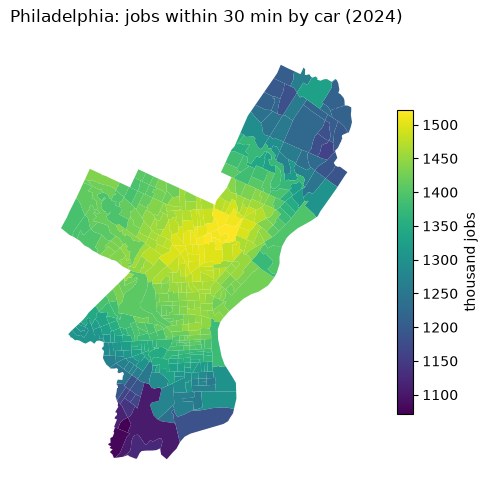

In [8]:
done = [m for m in METROS if m in set(acc.metro)]
fig, axes = plt.subplots(1, len(done), figsize=(6.5 * len(done), 5), squeeze=False)
for ax, name in zip(axes[0], done):
    fips = METROS[name]
    sub = tracts[tracts.GEOID.str[:5].isin(fips)].merge(acc, on="GEOID")
    sub.plot(column=sub.jobs_30min / 1000, ax=ax, cmap="viridis", legend=True,
             legend_kwds={"shrink": 0.7, "label": "thousand jobs"})
    ax.set_title(f"{name}: jobs within 30 min by car (2024)")
    ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "03_job_access.png", dpi=150)

## Save

- One row per tract. jobs_30min is blank outside the two metros

In [9]:
access = land.merge(acc[["GEOID", "jobs_30min", "metro"]], on="GEOID", how="left")
access.to_csv(OUT / "access_tract.csv", index=False)
print(len(access), "rows,", access.jobs_30min.notna().sum(), "with job access")

3445 rows, 408 with job access
